In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    mean_squared_error,
    r2_score,
)

print("Libraries loaded for data handling, EDA, visualization, preprocessing, KNN modeling, and evaluation.")

Libraries loaded for data handling, EDA, visualization, preprocessing, KNN modeling, and evaluation.


In [2]:
df = pd.read_csv("diabetes.csv")
print(f"Dataset loaded successfully: {df.shape[0]} records and {df.shape[1]} columns.")
display(df.head())

Dataset loaded successfully: 768 records and 9 columns.


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
print("Dataset dimensions:", df.shape)
print("\nColumn names and data types:")
df.info()
print("\nNumeric summary statistics:")
display(df.describe().round(2))
print("\nMissing values in each column:")
display(df.isna().sum().rename("Missing values").to_frame())
print("\nDiabetes outcome counts (0 = no diabetes, 1 = diabetes):")
display(df["Outcome"].value_counts().sort_index().rename(index={0: "No diabetes", 1: "Diabetes"}).to_frame("Records"))

Dataset dimensions: (768, 9)

Column names and data types:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Numeric summary statistics:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00
mean,3.85,120.89,69.11,20.54,79.80,31.99,0.47,33.24,0.35
std,3.37,31.97,19.36,15.95,115.24,7.88,0.33,11.76,0.48
min,0.00,0.00,0.00,0.00,0.00,0.00,0.08,21.00,0.00
25%,1.00,99.00,62.00,0.00,0.00,27.30,0.24,24.00,0.00
50%,3.00,117.00,72.00,23.00,30.50,32.00,0.37,29.00,0.00
75%,6.00,140.25,80.00,32.00,127.25,36.60,0.63,41.00,1.00
max,17.00,199.00,122.00,99.00,846.00,67.10,2.42,81.00,1.00



Missing values in each column:


,Missing values
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0



Diabetes outcome counts (0 = no diabetes, 1 = diabetes):


,Records
Outcome,
No diabetes,500
Diabetes,268


In [4]:
zero_invalid_cols = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
]

invalid_zero_counts = df[zero_invalid_cols].eq(0).sum()
df[zero_invalid_cols] = df[zero_invalid_cols].replace(0, np.nan)
for col in zero_invalid_cols:
    df[col] = df[col].fillna(df[col].median())

print("Invalid zero measurements replaced with their column medians:")
display(invalid_zero_counts.rename("Values imputed").to_frame())
print("Preview of cleaned measurements:")
display(df[zero_invalid_cols].head())

Invalid zero measurements replaced with their column medians:


,Values imputed
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11


Preview of cleaned measurements:


,Glucose,BloodPressure,SkinThickness,Insulin,BMI
0,148.0,72.0,35.0,125.0,33.6
1,85.0,66.0,29.0,125.0,26.6
2,183.0,64.0,29.0,125.0,23.3
3,89.0,66.0,23.0,94.0,28.1
4,137.0,40.0,35.0,168.0,43.1


Histogram: frequency distribution of cleaned glucose measurements.


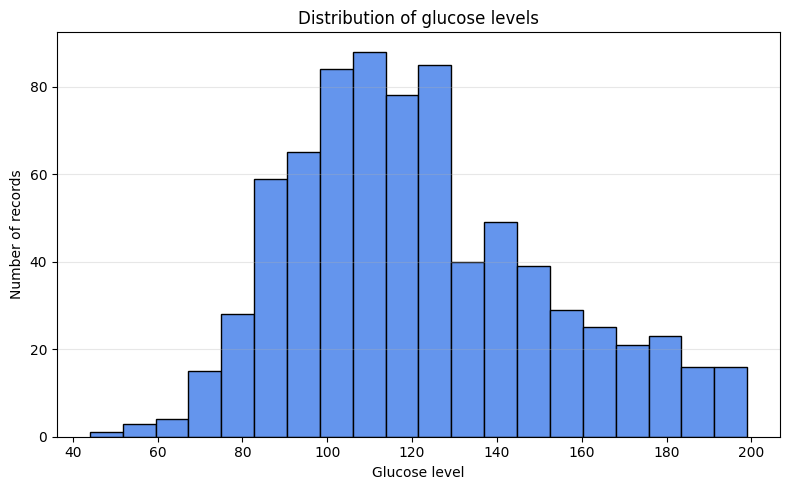

In [5]:
print("Histogram: frequency distribution of cleaned glucose measurements.")
plt.figure(figsize=(8, 5))
plt.hist(df["Glucose"], bins=20, color="cornflowerblue", edgecolor="black")
plt.xlabel("Glucose level")
plt.ylabel("Number of records")
plt.title("Distribution of glucose levels")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Scatter plot: glucose and BMI measurements grouped by diabetes outcome.


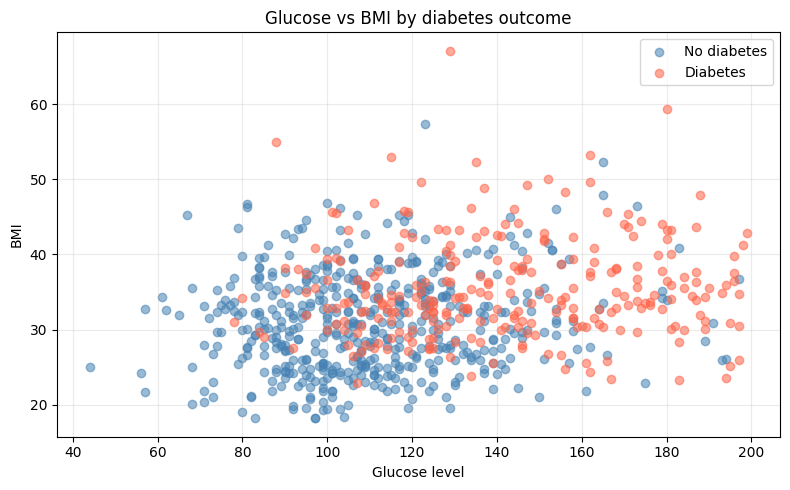

In [6]:
print("Scatter plot: glucose and BMI measurements grouped by diabetes outcome.")
plt.figure(figsize=(8, 5))
for outcome, label, color in [(0, "No diabetes", "steelblue"), (1, "Diabetes", "tomato")]:
    subset = df[df["Outcome"] == outcome]
    plt.scatter(subset["Glucose"], subset["BMI"], label=label, alpha=0.55, color=color)
plt.xlabel("Glucose level")
plt.ylabel("BMI")
plt.title("Glucose vs BMI by diabetes outcome")
plt.legend()
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

Box plot: BMI distribution for each diabetes outcome group.


<Figure size 700x500 with 0 Axes>

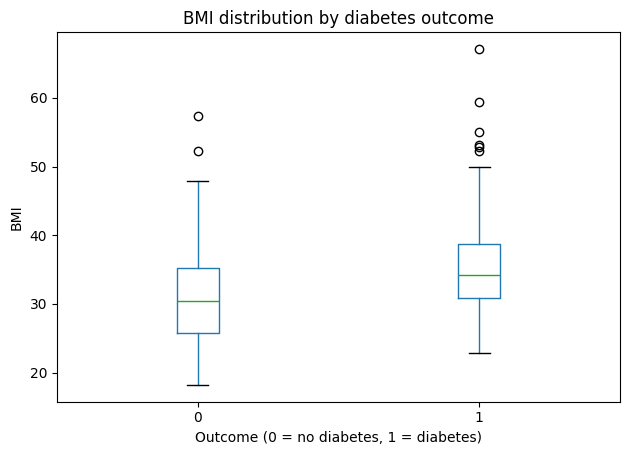

In [7]:
print("Box plot: BMI distribution for each diabetes outcome group.")
plt.figure(figsize=(7, 5))
df.boxplot(column="BMI", by="Outcome", grid=False)
plt.xlabel("Outcome (0 = no diabetes, 1 = diabetes)")
plt.ylabel("BMI")
plt.title("BMI distribution by diabetes outcome")
plt.suptitle("")
plt.tight_layout()
plt.show()

Heatmap: correlations between numeric measurements and diabetes outcome.


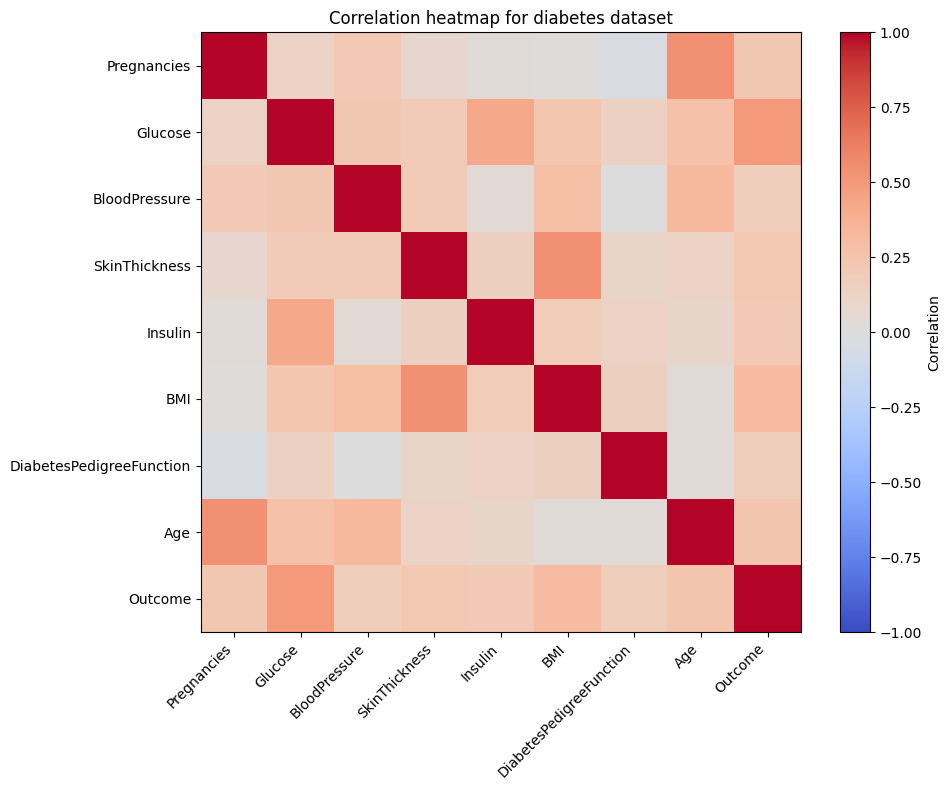

In [8]:
print("Heatmap: correlations between numeric measurements and diabetes outcome.")
correlation = df.corr(numeric_only=True)
plt.figure(figsize=(10, 8))
image = plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(image, label="Correlation")
plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=45, ha="right")
plt.yticks(range(len(correlation.columns)), correlation.columns)
plt.title("Correlation heatmap for diabetes dataset")
plt.tight_layout()
plt.show()

Bar plot: number of records with and without diabetes.


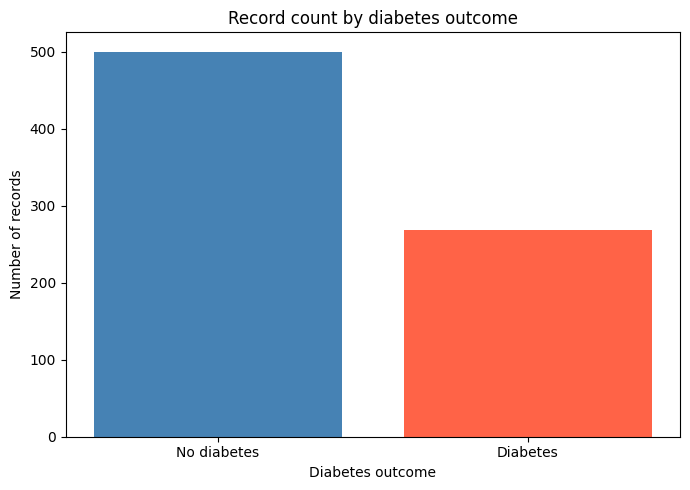

In [9]:
print("Bar plot: number of records with and without diabetes.")
outcome_counts = df["Outcome"].value_counts().reindex([0, 1], fill_value=0)
plt.figure(figsize=(7, 5))
plt.bar(["No diabetes", "Diabetes"], outcome_counts.values, color=["steelblue", "tomato"])
plt.xlabel("Diabetes outcome")
plt.ylabel("Number of records")
plt.title("Record count by diabetes outcome")
plt.tight_layout()
plt.show()

In [10]:
feature_cols = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
]

X_all = df[feature_cols].values
y_clf = df["Outcome"].values
print(f"Classification data prepared with {X_all.shape[0]} records and {X_all.shape[1]} features.")
print("Feature columns:", ", ".join(feature_cols))

Classification data prepared with 768 records and 8 features.
Feature columns: Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, DiabetesPedigreeFunction, Age


In [11]:
target_reg = "BMI"
feature_cols_reg = [col for col in feature_cols if col != target_reg]
X_reg = df[feature_cols_reg].values
y_reg = df[target_reg].values

print(f"Regression data prepared to predict {target_reg} from {len(feature_cols_reg)} features.")
print("Regression features:", ", ".join(feature_cols_reg))

Regression data prepared to predict BMI from 7 features.
Regression features: Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, DiabetesPedigreeFunction, Age


In [12]:
X_train_clf, X_test_clf, y_clf_train, y_clf_test = train_test_split(
    X_all,
    y_clf,
    test_size=0.3,
    random_state=42,
    stratify=y_clf,
)

X_train_reg, X_test_reg, y_reg_train, y_reg_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.3,
    random_state=42,
)

scaler_clf = StandardScaler()
print("Classification and regression data split into training and test sets.")
print(f"Classification records: {len(y_clf_train)} training, {len(y_clf_test)} test.")
print(f"Regression records: {len(y_reg_train)} training, {len(y_reg_test)} test.")

Classification and regression data split into training and test sets.
Classification records: 537 training, 231 test.
Regression records: 537 training, 231 test.


In [13]:
X_train_clf_scaled = scaler_clf.fit_transform(X_train_clf)
X_test_clf_scaled = scaler_clf.transform(X_test_clf)

scaler_reg = StandardScaler()
X_train_reg_scaled = scaler_reg.fit_transform(X_train_reg)
X_test_reg_scaled = scaler_reg.transform(X_test_reg)

print("Standardization complete; test features were transformed using training-set statistics.")

Standardization complete; test features were transformed using training-set statistics.


In [14]:
comparison = pd.DataFrame({
    "Original Mean": X_train_clf.mean(axis=0),
    "Original Std": X_train_clf.std(axis=0),
    "Scaled Mean": X_train_clf_scaled.mean(axis=0),
    "Scaled Std": X_train_clf_scaled.std(axis=0),
}, index=feature_cols)

print("Training feature statistics before and after standardization:")
display(comparison.round(3))

Training feature statistics before and after standardization:


,Original Mean,Original Std,Scaled Mean,Scaled Std
Pregnancies,3.883,3.347,0.0,1.0
Glucose,121.564,29.924,0.0,1.0
BloodPressure,72.227,12.175,-0.0,1.0
SkinThickness,28.886,8.251,0.0,1.0
Insulin,138.058,79.653,-0.0,1.0
BMI,32.616,6.724,0.0,1.0
DiabetesPedigreeFunction,0.481,0.335,-0.0,1.0
Age,33.551,11.784,-0.0,1.0


In [15]:
k = 5
knn = KNeighborsClassifier(n_neighbors=k)
knn.fit(X_train_clf_scaled, y_clf_train)
print(f"KNN classifier trained with k={k} using {len(y_clf_train)} training records.")

KNN classifier trained with k=5 using 537 training records.


In [16]:
y_pred = knn.predict(X_test_clf_scaled)
prediction_preview = pd.DataFrame({
    "Actual outcome": y_clf_test[:20],
    "Predicted outcome": y_pred[:20],
})
print("Actual and predicted diabetes outcomes for the first 20 test records:")
display(prediction_preview)

Actual and predicted diabetes outcomes for the first 20 test records:


,Actual outcome,Predicted outcome
0,1,0
1,1,0
2,1,1
3,1,1
4,1,0
5,0,0
6,0,1
7,0,0
8,0,0
9,0,0


In [17]:
y_prob = knn.predict_proba(X_test_clf_scaled)[:, 1]
probability_preview = pd.DataFrame({
    "Actual outcome": y_clf_test[:20],
    "Predicted diabetes probability": y_prob[:20],
})
print("Actual outcomes and predicted diabetes probabilities for the first 20 test records:")
display(probability_preview.round(3))

Actual outcomes and predicted diabetes probabilities for the first 20 test records:


,Actual outcome,Predicted diabetes probability
0,1,0.0
1,1,0.2
2,1,0.8
3,1,0.6
4,1,0.4
5,0,0.2
6,0,0.8
7,0,0.0
8,0,0.0
9,0,0.2


In [18]:
accuracy = accuracy_score(y_clf_test, y_pred)
print(f"Baseline KNN test accuracy: {accuracy:.4f} ({accuracy:.1%}).")

Baseline KNN test accuracy: 0.7446 (74.5%).


In [19]:
k_values = range(1, 31)
train_accuracy = []
test_accuracy = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_clf_scaled, y_clf_train)
    train_accuracy.append(model.score(X_train_clf_scaled, y_clf_train))
    test_accuracy.append(model.score(X_test_clf_scaled, y_clf_test))

print("Training and test accuracy calculated for neighbor counts from 1 through 30.")

Training and test accuracy calculated for neighbor counts from 1 through 30.


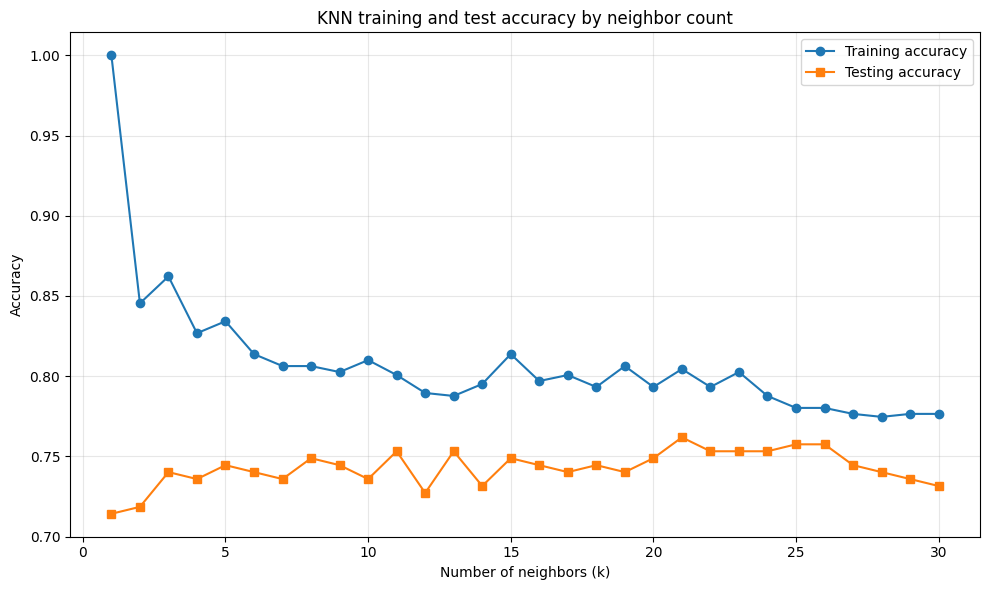

In [20]:
plt.figure(figsize=(10, 6))
plt.plot(k_values, train_accuracy, marker="o", label="Training accuracy")
plt.plot(k_values, test_accuracy, marker="s", label="Testing accuracy")
plt.xlabel("Number of neighbors (k)")
plt.ylabel("Accuracy")
plt.title("KNN training and test accuracy by neighbor count")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
best_k_accuracy = list(k_values)[int(np.argmax(test_accuracy))]
best_accuracy = max(test_accuracy)
print(f"Highest test accuracy in the k=1 to 30 comparison: {best_accuracy:.4f} ({best_accuracy:.1%}).")
print(f"Neighbor count with highest test accuracy: k={best_k_accuracy}.")

Highest test accuracy in the k=1 to 30 comparison: 0.7619 (76.2%).
Neighbor count with highest test accuracy: k=21.


In [22]:
cv_scores = []

for k in range(1, 31):
    knn_cv = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(
        knn_cv,
        X_train_clf_scaled,
        y_clf_train,
        cv=5,
        scoring="accuracy",
    )
    cv_scores.append(scores.mean())

best_k_cv = int(np.argmax(cv_scores)) + 1
print(f"Best neighbor count from 5-fold cross-validation: k={best_k_cv}.")
print(f"Mean cross-validation accuracy: {max(cv_scores):.4f} ({max(cv_scores):.1%}).")

Best neighbor count from 5-fold cross-validation: k=12.
Mean cross-validation accuracy: 0.7562 (75.6%).


In [23]:
param_grid = {
    "n_neighbors": list(range(3, 31, 2)),
    "weights": ["uniform", "distance"],
    "metric": ["euclidean", "manhattan", "minkowski"],
    "p": [1, 2],
}
print("Grid-search candidates configured for neighbor count, weights, distance metric, and Minkowski power.")

Grid-search candidates configured for neighbor count, weights, distance metric, and Minkowski power.


In [24]:
grid_search = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
)

grid_search.fit(X_train_clf_scaled, y_clf_train)

print("Grid search completed with 5-fold cross-validation.")
print("Best hyperparameters:", grid_search.best_params_)
print(f"Best mean cross-validation accuracy: {grid_search.best_score_:.4f} ({grid_search.best_score_:.1%}).")

Grid search completed with 5-fold cross-validation.
Best hyperparameters: {'metric': 'euclidean', 'n_neighbors': 11, 'p': 1, 'weights': 'uniform'}
Best mean cross-validation accuracy: 0.7543 (75.4%).


In [25]:
best_knn = grid_search.best_estimator_
test_acc = best_knn.score(X_test_clf_scaled, y_clf_test)
print(f"Tuned KNN accuracy on the held-out test set: {test_acc:.4f} ({test_acc:.1%}).")

Tuned KNN accuracy on the held-out test set: 0.7532 (75.3%).
